In [35]:
import numpy as np
import pandas as pd
import time
from codecarbon import EmissionsTracker, OfflineEmissionsTracker
import re
from transformers import BertModel, BertTokenizer
import torch
from scipy.stats import skew
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from tabulate import tabulate
import matplotlib.pyplot as plt
import torch.nn.functional as F

In [36]:
TEXT_COL = "summaries"
LABEL_COL = "terms"  # 相似度配对使用类别名列表，而非 multi-hot 向量

SAMPLE_SIZE = 200
NUM_QUANTILES = 100
RANDOM_SEED = 42
BATCH_SIZE = 64
MAX_TOKEN = 128

MODELS = [
    "google-bert/bert-base-uncased",
    "allenai/scibert_scivocab_uncased",
    "nlpaueb/legal-bert-base-uncased",
    "ahmedrachid/FinancialBERT",
    "Lianglab/PharmBERT-uncased",
    "recobo/agriculture-bert-uncased",
    "recobo/chemical-bert-uncased",
]
# 明确使用第一块 CUDA GPU；不可用时停止，不静默退回 CPU。
DEVICE = "cuda:0"


In [37]:
df = pd.read_csv("arxiv_data.csv")
df.head(10)

,titles,summaries,terms
0,Survey on Semantic Stereo Matching / Semantic ...,Stereo matching is one of the widely used tech...,"['cs.CV', 'cs.LG']"
1,FUTURE-AI: Guiding Principles and Consensus Re...,The recent advancements in artificial intellig...,"['cs.CV', 'cs.AI', 'cs.LG']"
2,Enforcing Mutual Consistency of Hard Regions f...,"In this paper, we proposed a novel mutual cons...","['cs.CV', 'cs.AI']"
3,Parameter Decoupling Strategy for Semi-supervi...,Consistency training has proven to be an advan...,['cs.CV']
4,Background-Foreground Segmentation for Interio...,"To ensure safety in automated driving, the cor...","['cs.CV', 'cs.LG']"
5,EdgeFlow: Achieving Practical Interactive Segm...,High-quality training data play a key role in ...,"['cs.CV', 'cs.HC']"
6,Efficient Hybrid Transformer: Learning Global-...,Semantic segmentation of fine-resolution urban...,['cs.CV']
7,Towards to Robust and Generalized Medical Imag...,"To mitigate the radiologist's workload, comput...","['cs.CV', 'cs.AI']"
8,Semi-supervised Meta-learning with Disentangle...,Generalising deep models to new data from new ...,['cs.CV']
9,Semi-supervised Contrastive Learning for Label...,The success of deep learning methods in medica...,['cs.CV']


In [38]:
print(df.shape)
print(type(df["terms"].iloc[0]))
import ast
from collections import Counter
from sklearn.preprocessing import MultiLabelBinarizer

# 在原始 terms 上统计文档频次；每篇文章中同一标签只计一次。
parsed_labels = df["terms"].map(
    lambda value: ast.literal_eval(value) if isinstance(value, str) else value
)
label_counts = Counter(
    label for labels in parsed_labels for label in set(labels)
)
top_9_labels = [label for label, _ in label_counts.most_common(9)]
top_9_set = set(top_9_labels)
original_size = len(df)

# 先直接修改 df：删除非前九类标签，再删除不含前九类的文章。
# terms 现在存储实际列表；保留的文章仍可含多个标签，不设置 Other 类。
df["terms"] = parsed_labels.map(
    lambda labels: list(dict.fromkeys(
        label for label in labels if label in top_9_set
    ))
)
df = df.loc[df["terms"].str.len().gt(0)].copy().reset_index(drop=True)

# 显式固定九个输出位置，顺序与 top_9_labels 一致。
mlb = MultiLabelBinarizer(classes=top_9_labels)
label_matrix = mlb.fit_transform(df["terms"])
df["labels"] = label_matrix.tolist()

print("保留的九大类别：", top_9_labels)
print("原始文章数量：", original_size)
print("保留文章数量：", len(df))
print("删除文章数量：", original_size - len(df))
print("Multi-hot 矩阵形状：", label_matrix.shape)
print("向量位置对应的标签顺序：", mlb.classes_.tolist())
display(df[["terms", "labels"]].head(10))
print(df.shape)
print(label_matrix.shape)

(51774, 3)
<class 'str'>
保留的九大类别： ['cs.CV', 'cs.LG', 'stat.ML', 'cs.AI', 'eess.IV', 'cs.RO', 'cs.CL', 'cs.NE', 'cs.CR']
原始文章数量： 51774
保留文章数量： 51774
删除文章数量： 0
Multi-hot 矩阵形状： (51774, 9)
向量位置对应的标签顺序： ['cs.CV', 'cs.LG', 'stat.ML', 'cs.AI', 'eess.IV', 'cs.RO', 'cs.CL', 'cs.NE', 'cs.CR']


,terms,labels
0,"[cs.CV, cs.LG]","[1, 1, 0, 0, 0, 0, 0, 0, 0]"
1,"[cs.CV, cs.AI, cs.LG]","[1, 1, 0, 1, 0, 0, 0, 0, 0]"
2,"[cs.CV, cs.AI]","[1, 0, 0, 1, 0, 0, 0, 0, 0]"
3,[cs.CV],"[1, 0, 0, 0, 0, 0, 0, 0, 0]"
4,"[cs.CV, cs.LG]","[1, 1, 0, 0, 0, 0, 0, 0, 0]"
5,[cs.CV],"[1, 0, 0, 0, 0, 0, 0, 0, 0]"
6,[cs.CV],"[1, 0, 0, 0, 0, 0, 0, 0, 0]"
7,"[cs.CV, cs.AI]","[1, 0, 0, 1, 0, 0, 0, 0, 0]"
8,[cs.CV],"[1, 0, 0, 0, 0, 0, 0, 0, 0]"
9,[cs.CV],"[1, 0, 0, 0, 0, 0, 0, 0, 0]"


(51774, 4)
(51774, 9)


In [39]:
def sample_from_length_groups(
    df,
    text_col,
    sample_size=200,
    num_quantiles=100,
    random_seed=42,
    length_fn=None,
    length_col="length",
    group_col="quantiles",
    return_grouped=False,
):
    """按文本长度分位组无放回抽样，不修改输入或依赖标签格式。

    默认长度是空白分隔词数。length_fn 可传入接收单篇文本并返回长度的函数，
    例如 len（字符数），或 lambda text: len(tokenizer.encode(text))。
    返回原有列和原始文本，并新增 length_col 和 group_col（Q1、Q2……）。
    缺失、空白文本不参与抽样。return_grouped=True 时返回
    (sampled_df, grouped_df)，后者包含全部有效文章的长度和分组，供后续复用。
    """
    if len({text_col, length_col, group_col}) != 3:
        raise ValueError("Text, length and group column names must be different")
    if length_col in df.columns or group_col in df.columns:
        raise ValueError("Length/group output columns already exist; choose unused output names")
    if text_col not in df.columns:
        raise ValueError(f"Missing text column: {text_col}")
    for name, value in [("sample_size", sample_size), ("num_quantiles", num_quantiles)]:
        if isinstance(value, bool) or not isinstance(value, (int, np.integer)) or value < 1:
            raise ValueError(f"{name} must be a positive integer")

    text = df[text_col].fillna("").astype(str).str.strip()
    pool = df.loc[text.ne("")].copy().reset_index(drop=True)
    text = text.loc[text.ne("")].reset_index(drop=True)
    if sample_size > len(pool):
        raise ValueError(f"Requested {sample_size} rows, but only {len(pool)} valid texts")

    lengths = text.str.split().str.len() if length_fn is None else text.map(length_fn)
    lengths = pd.to_numeric(lengths, errors="raise")
    if not np.isfinite(lengths.to_numpy(dtype=float)).all() or lengths.lt(0).any():
        raise ValueError("Text lengths must be finite, non-negative numbers")

    q = min(num_quantiles, sample_size, lengths.nunique())
    # 相同长度不拆组；所有文本长度相同时使用一个组。
    groups = (
        pd.Series(np.zeros(len(pool), dtype=int))
        if q <= 1 else pd.qcut(lengths, q=q, labels=False, duplicates="drop")
    )
    # 分组基于完整有效数据，而不是抽样后的数据。
    pool[length_col] = lengths.to_numpy()
    pool[group_col] = pd.Categorical(
        groups.map(lambda group: f"Q{int(group) + 1}"),
        categories=[f"Q{int(group) + 1}" for group in sorted(groups.unique())],
        ordered=True,
    )
    group_indices = list(groups.groupby(groups, sort=True).groups.values())
    rng = np.random.default_rng(random_seed)
    base_n = sample_size // len(group_indices)
    selected = []
    for indices in group_indices:
        selected.extend(rng.choice(
            np.asarray(indices), size=min(base_n, len(indices)), replace=False
        ).tolist())

    # 分位组不足或较小时，从未选中的行补足目标数量。
    remaining_n = sample_size - len(selected)
    if remaining_n:
        remaining_indices = np.setdiff1d(np.arange(len(pool)), selected)
        selected.extend(rng.choice(remaining_indices, size=remaining_n, replace=False).tolist())
    rng.shuffle(selected)
    sampled_df = pool.iloc[selected].copy().reset_index(drop=True)
    sampled_lengths = lengths.iloc[selected]
    print("Valid texts:", len(pool))
    print("Length groups:", len(group_indices))
    print("Actual sample size:", len(sampled_df))
    print("Length measure:", "whitespace word count" if length_fn is None else "custom length_fn")
    print("Sample length min / mean / max:",
          sampled_lengths.min(), sampled_lengths.mean(), sampled_lengths.max())
    return (sampled_df, pool) if return_grouped else sampled_df


In [40]:
sampled_df, grouped_df = sample_from_length_groups(
    df=df,
    text_col=TEXT_COL,
    sample_size=SAMPLE_SIZE,
    num_quantiles=NUM_QUANTILES,
    random_seed=RANDOM_SEED,
    length_col="length",
    group_col="quantiles",
    return_grouped=True,
)
display(sampled_df.head())

# grouped_df：全部有效文章；sampled_df：抽样文章，两者均保留长度和分组。
display(grouped_df[[TEXT_COL, "length", "quantiles"]].head())


Valid texts: 51774
Length groups: 100
Actual sample size: 200
Length measure: whitespace word count
Sample length min / mean / max: 67 173.64 295


,titles,summaries,terms,labels,length,quantiles
0,A short variational proof of equivalence betwe...,Two main families of reinforcement learning al...,[cs.LG],"[0, 1, 0, 0, 0, 0, 0, 0, 0]",89,Q3
1,Transformer for Image Quality Assessment,Transformer has become the new standard method...,"[cs.CV, cs.LG, eess.IV]","[1, 1, 0, 0, 1, 0, 0, 0, 0]",118,Q11
2,Local Facial Attribute Transfer through Inpain...,The term attribute transfer refers to the task...,"[cs.CV, eess.IV]","[1, 0, 0, 0, 1, 0, 0, 0, 0]",203,Q76
3,Semantic Segmentation for Real Point Cloud Sce...,"Given the prominence of current 3D sensors, a ...",[cs.CV],"[1, 0, 0, 0, 0, 0, 0, 0, 0]",158,Q39
4,LeafGAN: An Effective Data Augmentation Method...,Many applications for the automated diagnosis ...,[cs.CV],"[1, 0, 0, 0, 0, 0, 0, 0, 0]",180,Q58


,summaries,length,quantiles
0,Stereo matching is one of the widely used tech...,132,Q19
1,The recent advancements in artificial intellig...,206,Q78
2,"In this paper, we proposed a novel mutual cons...",227,Q88
3,Consistency training has proven to be an advan...,198,Q72
4,"To ensure safety in automated driving, the cor...",274,Q99


In [41]:
from transformers import (
    AutoTokenizer,
    AutoModel,
)


def compute_embeddings(
    texts,
    model_name,
    batch_size=64,
    max_token=128,
):
    # Auto classes support all seven model checkpoints
    tokenizer = AutoTokenizer.from_pretrained(
        model_name,
        use_fast=True,
    )

    model = AutoModel.from_pretrained(
        model_name,
    )

    if not torch.cuda.is_available():
        raise RuntimeError("CUDA unavailable: select the CUDA-enabled Python environment")
    device = torch.device(DEVICE)
    print("GPU:", torch.cuda.get_device_name(device), flush=True)

    model = model.to(device)
    model.eval()

    all_embeddings = []

    for start_index in range(
        0,
        len(texts),
        batch_size,
    ):
        batch_texts = texts[
            start_index:
            start_index + batch_size
        ]

        inputs = tokenizer(
            batch_texts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=max_token,
        )

        inputs = {
            key: value.to(device)
            for key, value in inputs.items()
        }

        with torch.inference_mode():
            outputs = model(**inputs)

            token_embeddings = (
                outputs.last_hidden_state
            )

            # Shape:
            # attention_mask:
            # [batch_size, sequence_length]
            #
            # expanded_mask:
            # [batch_size, sequence_length, 1]
            expanded_mask = (
                inputs["attention_mask"]
                .unsqueeze(-1)
                .to(token_embeddings.dtype)
            )

            # Sum only real-token embeddings
            summed_embeddings = (
                token_embeddings
                * expanded_mask
            ).sum(dim=1)

            # Number of real tokens in each text
            valid_token_counts = (
                expanded_mask
                .sum(dim=1)
                .clamp(min=1e-9)
            )

            # Masked mean pooling
            batch_embeddings = (
                summed_embeddings
                / valid_token_counts
            )

        all_embeddings.append(
            batch_embeddings.cpu()
        )

    embeddings = torch.cat(
        all_embeddings,
        dim=0,
    )

    print(
        "Model:",
        model_name,
    )
    print(
        "Device:",
        device,
    )
    print(
        "Embedding shape:",
        tuple(embeddings.shape),
    )

    return embeddings

In [42]:
def asymmetry_eta(x, bandwidth=None):
    """
    Estimate eta using Patil et al.-style estimator:
    eta_hat = -Corr(f_hat(X_i), F_hat(X_i))

    f_hat(X_i): leave-one-out Gaussian KDE
    F_hat(X_i): leave-one-out empirical CDF
    """
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    n = len(x)

    if n < 3:
        return np.nan

    # Silverman's bandwidth
    s = np.std(x, ddof=1)
    iqr = np.subtract(*np.percentile(x, [75, 25]))
    sigma = min(s, iqr / 1.349) if iqr > 0 else s
    if np.isclose(sigma, 0):
        sigma = s if s > 0 else 1.0
    h = bandwidth if bandwidth is not None else 0.9 * sigma * (n ** (-1 / 5))#calculate bandwidth
    if h <= 0:
        h = 1.06 * (s if s > 0 else 1.0) * (n ** (-1 / 5))

    # Leave-one-out KDE
    diffs = (x[None, :] - x[:, None]) / h#cal culate pairwise difference
    K = stats.norm.pdf(diffs)#fit standardized distance into gaussian kernel
    np.fill_diagonal(K, 0.0)#leave one out
    f_hat = K.sum(axis=1) / ((n - 1) * h)#KED for pdf

    # Leave-one-out empirical CDF
    indicators = (x[None, :] < x[:, None]).astype(float)
    np.fill_diagonal(indicators, 0.0)
    F_hat = indicators.sum(axis=1) / (n - 1)

    if np.std(f_hat, ddof=1) == 0 or np.std(F_hat, ddof=1) == 0:
        return np.nan

    eta = -np.corrcoef(f_hat, F_hat)[0, 1]#calculate correlation

    return eta

In [43]:
def chi2_distance(dist1, dist2, bins=50, value_range=None, eps=1e-12):

    hist1, bin_edges = np.histogram(dist1, bins=bins, range=value_range)
    hist2, _ = np.histogram(dist2, bins=bin_edges)

    p = hist1 / hist1.sum()
    q = hist2 / hist2.sum()

    chi_dist = 0.5 * np.sum((p - q) ** 2 / (p + q + eps))

    return chi_dist

In [44]:
def create_cosine_similarity_matrix(
    embeddings,
):
    normalized_embeddings = F.normalize(
        embeddings.detach().cpu().float(),
        p=2,
        dim=1,
    )

    similarity_matrix = (
        normalized_embeddings
        @ normalized_embeddings.T
    )

    return similarity_matrix.numpy()

In [45]:
from collections import defaultdict
from itertools import combinations

import numpy as np


def convert_to_label_sets(labels):
    label_sets = []

    for document_labels in labels:
        if isinstance(
            document_labels,
            str,
        ):
            label_set = {
                document_labels
            }
        else:
            label_set = set(
                document_labels
            )

        label_sets.append(
            label_set
        )

    return label_sets

In [46]:
def calculate_within_label_cosine_distribution(
    embeddings,
    labels,
    return_by_label=True,
):
    label_sets = convert_to_label_sets(
        labels
    )

    similarity_matrix = (
        create_cosine_similarity_matrix(
            embeddings
        )
    )

    all_scores = []

    scores_by_label = defaultdict(
        list
    )

    number_of_documents = len(
        label_sets
    )

    for first_index, second_index in combinations(
        range(number_of_documents),
        2,
    ):
        shared_labels = (
            label_sets[first_index]
            .intersection(
                label_sets[second_index]
            )
        )

        # Same-label means at least one
        # shared label.
        if not shared_labels:
            continue

        score = float(
            similarity_matrix[
                first_index,
                second_index,
            ]
        )

        # Add once to the overall distribution,
        # regardless of how many labels are shared.
        all_scores.append(
            score
        )

        # Per-label diagnostic data.
        # The score can appear in multiple label
        # groups here, but not in all_scores.
        for label in shared_labels:
            scores_by_label[
                label
            ].append(score)

    all_scores = np.asarray(
        all_scores,
        dtype=float,
    )

    if len(all_scores) == 0:
        raise ValueError(
            "No within-label document "
            "pairs were found."
        )

    scores_by_label = {
        label: np.asarray(
            label_scores,
            dtype=float,
        )
        for label, label_scores
        in sorted(
            scores_by_label.items()
        )
    }

    print(
        "Total unique within-label "
        "document pairs:",
        len(all_scores),
    )

    if return_by_label:
        return (
            all_scores,
            scores_by_label,
        )

    return all_scores

In [47]:
def calculate_between_label_cosine_distribution(
    embeddings,
    labels,
    return_by_label_pair=True,
):
    label_sets = convert_to_label_sets(
        labels
    )

    similarity_matrix = (
        create_cosine_similarity_matrix(
            embeddings
        )
    )

    all_scores = []

    scores_by_label_pair = defaultdict(
        list
    )

    number_of_documents = len(
        label_sets
    )

    for first_index, second_index in combinations(
        range(number_of_documents),
        2,
    ):
        first_label_set = (
            label_sets[first_index]
        )

        second_label_set = (
            label_sets[second_index]
        )

        # Different-label means no shared labels.
        if not first_label_set.isdisjoint(
            second_label_set
        ):
            continue

        score = float(
            similarity_matrix[
                first_index,
                second_index,
            ]
        )

        # Add each document pair exactly once.
        all_scores.append(
            score
        )

        # Store the full label-set pair only
        # for diagnostic purposes.
        first_key = tuple(
            sorted(first_label_set)
        )

        second_key = tuple(
            sorted(second_label_set)
        )

        label_set_pair = tuple(
            sorted(
                (
                    first_key,
                    second_key,
                )
            )
        )

        scores_by_label_pair[
            label_set_pair
        ].append(score)

    all_scores = np.asarray(
        all_scores,
        dtype=float,
    )

    if len(all_scores) == 0:
        raise ValueError(
            "No between-label document "
            "pairs were found."
        )

    scores_by_label_pair = {
        label_pair: np.asarray(
            pair_scores,
            dtype=float,
        )
        for label_pair, pair_scores
        in scores_by_label_pair.items()
    }

    print(
        "Number of label-set pair types:",
        len(scores_by_label_pair),
    )

    print(
        "Total unique between-label "
        "document pairs:",
        len(all_scores),
    )

    if return_by_label_pair:
        return (
            all_scores,
            scores_by_label_pair,
        )

    return all_scores

In [48]:
def bootstrap_chi2_from_existing_scores(
    same_scores,
    diff_label,
    n_bootstrap=1000,
    random_seed=42,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None
):

    rng = np.random.default_rng(random_seed)

    same_scores = np.asarray(same_scores)
    target_size = len(same_scores)

    # same-label statistics, fixed across bootstrap
    same_mean = same_scores.mean()
    same_eta = asymmetry_eta(same_scores, bandwidth=eta_bandwidth)
    same_abs_eta = abs(same_eta)

    label_pairs = list(diff_label.keys())
    n_pair_types = len(label_pairs)

    base_n = target_size // n_pair_types
    remainder = target_size % n_pair_types

    bootstrap_rows = []

    print("Same-label target size:", target_size)
    print("Different-label pair types:", n_pair_types)
    print("Base sample per diff-label pair:", base_n)

    for b in range(n_bootstrap):
        sampled_diff_scores = []

        for k, pair in enumerate(label_pairs):
            # already-computed cosine similarity scores for this label pair
            cosine_scores_for_this_pair = np.asarray(diff_label[pair])

            n_sample = base_n + (1 if k < remainder else 0)

            sampled_cosine_scores = rng.choice(
                cosine_scores_for_this_pair,
                size=n_sample,
                replace=True
            )

            sampled_diff_scores.extend(sampled_cosine_scores)

        sampled_diff_scores = np.asarray(sampled_diff_scores)

        # chi-square distance between same-label and bootstrapped diff-label distributions
        chi2_dist = chi2_distance(
            dist1=same_scores,
            dist2=sampled_diff_scores,
            bins=bins,
            value_range=value_range
        )

        # bootstrap diff-label statistics
        diff_mean = sampled_diff_scores.mean()
        diff_eta = asymmetry_eta(sampled_diff_scores, bandwidth=eta_bandwidth)
        diff_abs_eta = abs(diff_eta)

        mean_gap = same_mean - diff_mean
        abs_mean_gap = abs(mean_gap)

        eta_gap = same_eta - diff_eta
        abs_eta_gap = abs(eta_gap)

        chi2_result = {
            "bootstrap": b + 1,

            # same-label statistics, fixed
            "same_mean": same_mean,
            "same_eta": same_eta,
            "same_abs_eta": same_abs_eta,

            # bootstrapped diff-label statistics
            "diff_mean": diff_mean,
            "diff_eta": diff_eta,
            "diff_abs_eta": diff_abs_eta,

            # gaps
            "mean_gap": mean_gap,
            "abs_mean_gap": abs_mean_gap,
            "eta_gap": eta_gap,
            "abs_eta_gap": abs_eta_gap,

            # distribution distance
            "chi2_distance": chi2_dist,

            # pair numbers
            "same_n_pairs": len(same_scores),
            "diff_n_pairs": len(sampled_diff_scores)
        }

        bootstrap_rows.append(chi2_result)

    bootstrap_chi2_df = pd.DataFrame(bootstrap_rows)

    chi2_summary = {
        # same-label statistics
        "same_mean": same_mean,
        "same_eta": same_eta,
        "same_abs_eta": same_abs_eta,

        # averaged bootstrapped diff-label statistics
        "diff_mean": bootstrap_chi2_df["diff_mean"].mean(),
        "diff_mean_std": bootstrap_chi2_df["diff_mean"].std(),

        "diff_eta": bootstrap_chi2_df["diff_eta"].mean(),
        "diff_eta_std": bootstrap_chi2_df["diff_eta"].std(),
        "diff_abs_eta": bootstrap_chi2_df["diff_abs_eta"].mean(),

        # averaged gaps
        "mean_gap": bootstrap_chi2_df["mean_gap"].mean(),
        "mean_gap_std": bootstrap_chi2_df["mean_gap"].std(),
        "abs_mean_gap": bootstrap_chi2_df["abs_mean_gap"].mean(),

        "eta_gap": bootstrap_chi2_df["eta_gap"].mean(),
        "eta_gap_std": bootstrap_chi2_df["eta_gap"].std(),
        "abs_eta_gap": bootstrap_chi2_df["abs_eta_gap"].mean(),

        # averaged chi-square distance
        "chi2_distance": bootstrap_chi2_df["chi2_distance"].mean(),
        "chi2_distance_std": bootstrap_chi2_df["chi2_distance"].std(),

        # metadata
        "same_n_pairs": len(same_scores),
        "diff_n_pairs": bootstrap_chi2_df["diff_n_pairs"].mean(),
        "n_bootstrap": n_bootstrap,
        "bins": bins,
        "value_range": value_range
    }

    return bootstrap_chi2_df, chi2_summary

In [49]:
def run_one_model_chi2_bootstrap(
    sampled_df,
    model_name,
    batch_size=64,
    max_token=128,
    text_col="training_text",
    label_col="labels",
    n_bootstrap=1000,
    random_seed=42,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None,
):
    print(
        f"\nRunning model: {model_name}"
    )

    # Ohsumed text and multi-label columns
    texts = (
        sampled_df[text_col]
        .astype(str)
        .tolist()
    )

    # Keep labels as list of lists:
    # [["C01"], ["C02", "C03"], ...]
    labels = (
        sampled_df[label_col]
        .tolist()
    )

    # 1. Compute pretrained embeddings once
    embeddings = compute_embeddings(
        texts=texts,
        model_name=model_name,
        batch_size=batch_size,
        max_token=max_token,
    )

    # 2. Same-label cosine distribution
    same_scores, scores_by_label = (
        calculate_within_label_cosine_distribution(
            embeddings=embeddings,
            labels=labels,
            return_by_label=True,
        )
    )

    # 3. Different-label cosine distribution
    diff_scores_original, diff_label = (
        calculate_between_label_cosine_distribution(
            embeddings=embeddings,
            labels=labels,
            return_by_label_pair=True,
        )
    )

    # 4. Bootstrap the already-computed
    # different-label cosine scores
    (
        bootstrap_chi2_df,
        chi2_summary,
    ) = bootstrap_chi2_from_existing_scores(
        same_scores=same_scores,
        diff_label=diff_label,
        n_bootstrap=n_bootstrap,
        random_seed=random_seed,
        bins=bins,
        value_range=value_range,
        eta_bandwidth=eta_bandwidth,
    )

    # 5. Create one summary row for this model
    summary = {
        "model": model_name,

        # Same-label distribution
        "same_mean":
            chi2_summary["same_mean"],

        "same_eta":
            chi2_summary["same_eta"],

        "same_abs_eta":
            chi2_summary["same_abs_eta"],

        "same_n_pairs":
            chi2_summary["same_n_pairs"],

        # Bootstrapped different-label distribution
        "diff_mean":
            chi2_summary["diff_mean"],

        "diff_mean_std":
            chi2_summary["diff_mean_std"],

        "diff_eta":
            chi2_summary["diff_eta"],

        "diff_eta_std":
            chi2_summary["diff_eta_std"],

        "diff_abs_eta":
            chi2_summary["diff_abs_eta"],

        "diff_n_pairs":
            chi2_summary["diff_n_pairs"],

        # Same–different gaps
        "mean_gap":
            chi2_summary["mean_gap"],

        "mean_gap_std":
            chi2_summary["mean_gap_std"],

        "abs_mean_gap":
            chi2_summary["abs_mean_gap"],

        "eta_gap":
            chi2_summary["eta_gap"],

        "eta_gap_std":
            chi2_summary["eta_gap_std"],

        "abs_eta_gap":
            chi2_summary["abs_eta_gap"],

        # Distribution distance
        "chi2_distance":
            chi2_summary["chi2_distance"],

        "chi2_distance_std":
            chi2_summary[
                "chi2_distance_std"
            ],

        # Original pair count before bootstrap
        "diff_original_n_pairs":
            len(diff_scores_original),

        # Experimental settings
        "n_bootstrap": n_bootstrap,
        "bins": bins,
        "value_range": value_range,
        "batch_size": batch_size,
        "max_token": max_token,
        "random_seed": random_seed,
    }

    print("\nSummary:")
    print(
        "Same mean:",
        summary["same_mean"],
    )
    print(
        "Different mean:",
        summary["diff_mean"],
    )
    print(
        "Mean gap:",
        summary["mean_gap"],
    )
    print(
        "Same eta:",
        summary["same_eta"],
    )
    print(
        "Different eta:",
        summary["diff_eta"],
    )
    print(
        "Different |eta|:",
        summary["diff_abs_eta"],
    )
    print(
        "Eta gap:",
        summary["eta_gap"],
    )
    print(
        "Chi-square distance:",
        summary["chi2_distance"],
    )
    print(
        "Chi-square bootstrap std:",
        summary["chi2_distance_std"],
    )

    return {
        # Final row used for model comparison
        "summary": summary,

        # Original cosine distributions
        "same_scores": same_scores,
        "diff_scores_original":
            diff_scores_original,

        # Scores grouped by labels
        "scores_by_label":
            scores_by_label,
        "diff_label":
            diff_label,

        # All 1000 bootstrap metric rows
        "bootstrap_chi2_df":
            bootstrap_chi2_df,

        # Bootstrap summary dictionary
        "chi2_summary":
            chi2_summary,

        # Model outputs and corresponding data
        "embeddings": embeddings,
        "labels": labels,
        "document_ids": (
                sampled_df["document_id"].tolist()
                if "document_id" in sampled_df.columns
                else sampled_df.index.astype(str).tolist()
            ),
        # Preserve the exact sampled data
        "sampled_df":
            sampled_df.copy(),
    }

In [50]:
def metric_collect(
    grouped_df,
    sample_size=200,
    num_quantiles=100,
    num_repetitions=3,
    models=None,
    batch_size=64,
    max_token=128,
    text_col=None,
    label_col=None,
    n_bootstrap=1000,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None,
    master_seed=42,
    length_fn=None,
    length_col="length",
    group_col="quantiles",
):
    if text_col is None or label_col is None:
        raise ValueError("Pass text_col and label_col explicitly for the current dataset")
    missing = {text_col, label_col} - set(grouped_df.columns)
    if missing:
        raise ValueError(f"Missing columns: {sorted(missing)}")
    if num_repetitions < 1:
        raise ValueError("num_repetitions must be at least 1")
    if length_col == label_col or group_col == label_col:
        raise ValueError("Length/group column names must differ from label_col")
    if models is None:
        models = MODELS

    # 允许传入原始 df 或已经带长度分组的 grouped_df。
    # 在副本上移除派生列，由统一 sampler 按当前参数重新生成。
    sampling_pool = grouped_df.drop(columns=[length_col, group_col], errors="ignore").copy()
    # 保留可追踪的原始行标识，不使用抽样后重新编号的 index。
    if "document_id" not in sampling_pool.columns:
        if not sampling_pool.index.is_unique:
            raise ValueError("Provide a unique document_id when the input index is not unique")
        sampling_pool["document_id"] = sampling_pool.index.map(str)


    summary_results = []
    full_results = {}

    # Produce reproducible but different seeds
    # for different repetitions
    seed_generator = (
        np.random.default_rng(
            master_seed
        )
    )

    repetition_seeds = (
        seed_generator.integers(
            low=0,
            high=2**32 - 1,
            size=num_repetitions,
            dtype=np.uint32,
        )
    )

    for repetition in range(
        num_repetitions
    ):
        print(
            "================================"
            "================="
        )
        print(
            f"Repetition "
            f"{repetition + 1}/"
            f"{num_repetitions}"
        )

        repetition_seed = int(
            repetition_seeds[repetition]
        )

        print(
            "Repetition seed:",
            repetition_seed,
        )

        # 1. Draw one length-stratified sample
        sampled_df = (
            sample_from_length_groups(
                df=sampling_pool,
                text_col=text_col,
                length_fn=length_fn,
                length_col=length_col,
                group_col=group_col,
                return_grouped=False,
                sample_size=sample_size,
                num_quantiles=(
                    num_quantiles
                ),
                random_seed=(
                    repetition_seed
                )
            )
        )

        print(
            "Actual sample size:",
            len(sampled_df),
        )

        # Correct multi-label counting
        label_counts = (
            sampled_df[label_col]
            .explode()
            .value_counts()
            .sort_index()
        )

        print("Label counts:")
        print(label_counts)

        print(
            "Number of represented labels:",
            len(label_counts),
        )

        # 2. Every model uses exactly the same
        # sample in this repetition
        for model_name in models:
            result = (
                run_one_model_chi2_bootstrap(
                    sampled_df=sampled_df,
                    model_name=model_name,
                    batch_size=batch_size,
                    max_token=max_token,
                    text_col=text_col,
                    label_col=label_col,
                    n_bootstrap=n_bootstrap,
                    random_seed=(
                        repetition_seed
                    ),
                    bins=bins,
                    value_range=(
                        value_range
                    ),
                    eta_bandwidth=(
                        eta_bandwidth
                    ),
                )
            )

            summary = (
                result["summary"].copy()
            )

            summary["repetition"] = (
                repetition + 1
            )

            summary["random_seed"] = (
                repetition_seed
            )

            summary["sample_size"] = (
                sample_size
            )

            summary[
                "num_quantiles"
            ] = num_quantiles

            summary[
                "represented_labels"
            ] = len(label_counts)

            summary_results.append(
                summary
            )

            full_results[
                (
                    repetition + 1,
                    model_name,
                )
            ] = result

    summary_df = pd.DataFrame(
        summary_results
    )

    return {
        "summary_df": summary_df,
        "full_results": full_results,
        "repetition_seeds": (
            repetition_seeds.tolist()
        ),
    }

In [51]:
results = metric_collect(
    grouped_df=df,
    sample_size=SAMPLE_SIZE,
    num_quantiles=NUM_QUANTILES,
    num_repetitions=3,
    models=MODELS,
    batch_size=BATCH_SIZE,
    max_token=MAX_TOKEN,
    text_col=TEXT_COL,
    label_col=LABEL_COL,
    n_bootstrap=1000,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None,
    master_seed=RANDOM_SEED,
)

summary_df = results["summary_df"]
summary_df

Repetition 1/3
Repetition seed: 383329927
Valid texts: 51774
Length groups: 100
Actual sample size: 200
Length measure: whitespace word count
Sample length min / mean / max: 74 173.645 300
Actual sample size: 200
Label counts:
terms
cs.AI       19
cs.CL        7
cs.CR        2
cs.CV      126
cs.LG      104
cs.NE        9
cs.RO        8
eess.IV     10
stat.ML     57
Name: count, dtype: int64
Number of represented labels: 9

Running model: google-bert/bert-base-uncased


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


GPU: NVIDIA GeForce RTX 5080
Model: google-bert/bert-base-uncased
Device: cuda:0
Embedding shape: (200, 768)
Total unique within-label document pairs: 12894
Number of label-set pair types: 77
Total unique between-label document pairs: 7006
Same-label target size: 12894
Different-label pair types: 77
Base sample per diff-label pair: 167

Summary:
Same mean: 0.8882981385577459
Different mean: 0.8803952304991305
Mean gap: 0.007902908058615411
Same eta: -0.4650496697914601
Different eta: -0.15308506230551144
Different |eta|: 0.15308506230551144
Eta gap: -0.31196460748594873
Chi-square distance: 0.027647288375993916
Chi-square bootstrap std: 0.001079656201352488

Running model: allenai/scibert_scivocab_uncased


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: allenai/scibert_scivocab_uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (55 outputs left out)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

BertModel LOAD REPORT from: recobo/chemical-bert-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
bert.embeddings.position_ids               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


GPU: NVIDIA GeForce RTX 5080
Model: recobo/chemical-bert-uncased
Device: cuda:0
Embedding shape: (200, 768)
Total unique within-label document pairs: 12843
Number of label-set pair types: 74
Total unique between-label document pairs: 7057
Same-label target size: 12843
Different-label pair types: 74
Base sample per diff-label pair: 173

Summary:
Same mean: 0.9373246414967901
Different mean: 0.9322234096200975
Mean gap: 0.005101231876692567
Same eta: -0.3897641101572121
Different eta: -0.28068000133034743
Different |eta|: 0.28068000133034743
Eta gap: -0.10908410882686463
Chi-square distance: 0.015159412382568797
Chi-square bootstrap std: 0.0008490612801493842


,model,same_mean,same_eta,same_abs_eta,same_n_pairs,diff_mean,diff_mean_std,diff_eta,diff_eta_std,diff_abs_eta,...,n_bootstrap,bins,value_range,batch_size,max_token,random_seed,repetition,sample_size,num_quantiles,represented_labels
0,google-bert/bert-base-uncased,0.888298,-0.465050,0.465050,12894,0.880395,0.000195,-0.153085,0.010422,0.153085,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,9
1,allenai/scibert_scivocab_uncased,0.883415,-0.379827,0.379827,12894,0.881037,0.000173,-0.146232,0.010270,0.146232,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,9
2,nlpaueb/legal-bert-base-uncased,0.946335,-0.302596,0.302596,12894,0.945176,0.000085,0.047101,0.009774,0.047101,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,9
3,ahmedrachid/FinancialBERT,0.901351,-0.320619,0.320619,12894,0.901573,0.000170,-0.155612,0.008666,0.155612,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,9
4,Lianglab/PharmBERT-uncased,0.876813,-0.340548,0.340548,12894,0.870923,0.000194,-0.263410,0.011620,0.263410,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,9
5,recobo/agriculture-bert-uncased,0.908665,-0.364636,0.364636,12894,0.903999,0.000135,-0.037247,0.012079,0.037249,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,9
6,recobo/chemical-bert-uncased,0.936321,-0.378121,0.378121,12894,0.933369,0.000113,0.091688,0.012340,0.091688,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,9
7,google-bert/bert-base-uncased,0.887259,-0.465457,0.465457,12685,0.882546,0.000165,-0.241200,0.012011,0.241200,...,1000,50,"(-1, 1)",64,128,3324115916,2,200,100,9
8,allenai/scibert_scivocab_uncased,0.882068,-0.275051,0.275051,12685,0.876692,0.000149,-0.276074,0.011469,0.276074,...,1000,50,"(-1, 1)",64,128,3324115916,2,200,100,9
9,nlpaueb/legal-bert-base-uncased,0.946370,-0.317683,0.317683,12685,0.945668,0.000070,-0.168588,0.013707,0.168588,...,1000,50,"(-1, 1)",64,128,3324115916,2,200,100,9


In [52]:
summary_df = results[
    "summary_df"
]

display(summary_df)

,model,same_mean,same_eta,same_abs_eta,same_n_pairs,diff_mean,diff_mean_std,diff_eta,diff_eta_std,diff_abs_eta,...,n_bootstrap,bins,value_range,batch_size,max_token,random_seed,repetition,sample_size,num_quantiles,represented_labels
0,google-bert/bert-base-uncased,0.888298,-0.465050,0.465050,12894,0.880395,0.000195,-0.153085,0.010422,0.153085,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,9
1,allenai/scibert_scivocab_uncased,0.883415,-0.379827,0.379827,12894,0.881037,0.000173,-0.146232,0.010270,0.146232,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,9
2,nlpaueb/legal-bert-base-uncased,0.946335,-0.302596,0.302596,12894,0.945176,0.000085,0.047101,0.009774,0.047101,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,9
3,ahmedrachid/FinancialBERT,0.901351,-0.320619,0.320619,12894,0.901573,0.000170,-0.155612,0.008666,0.155612,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,9
4,Lianglab/PharmBERT-uncased,0.876813,-0.340548,0.340548,12894,0.870923,0.000194,-0.263410,0.011620,0.263410,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,9
5,recobo/agriculture-bert-uncased,0.908665,-0.364636,0.364636,12894,0.903999,0.000135,-0.037247,0.012079,0.037249,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,9
6,recobo/chemical-bert-uncased,0.936321,-0.378121,0.378121,12894,0.933369,0.000113,0.091688,0.012340,0.091688,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,9
7,google-bert/bert-base-uncased,0.887259,-0.465457,0.465457,12685,0.882546,0.000165,-0.241200,0.012011,0.241200,...,1000,50,"(-1, 1)",64,128,3324115916,2,200,100,9
8,allenai/scibert_scivocab_uncased,0.882068,-0.275051,0.275051,12685,0.876692,0.000149,-0.276074,0.011469,0.276074,...,1000,50,"(-1, 1)",64,128,3324115916,2,200,100,9
9,nlpaueb/legal-bert-base-uncased,0.946370,-0.317683,0.317683,12685,0.945668,0.000070,-0.168588,0.013707,0.168588,...,1000,50,"(-1, 1)",64,128,3324115916,2,200,100,9


In [53]:
metric_summary_df = (
    summary_df
    .groupby(
        "model",
        as_index=False,
    )
    .agg(
        # Same-label mean
        same_mean_mean=(
            "same_mean",
            "mean",
        ),
        same_mean_sampling_std=(
            "same_mean",
            "std",
        ),

        # Different-label mean
        diff_mean_mean=(
            "diff_mean",
            "mean",
        ),
        diff_mean_sampling_std=(
            "diff_mean",
            "std",
        ),

        # Average uncertainty from
        # the 1000 bootstrap runs
        diff_mean_bootstrap_std_mean=(
            "diff_mean_std",
            "mean",
        ),

        # Same-label eta
        same_eta_mean=(
            "same_eta",
            "mean",
        ),
        same_eta_sampling_std=(
            "same_eta",
            "std",
        ),

        same_abs_eta_mean=(
            "same_abs_eta",
            "mean",
        ),
        same_abs_eta_sampling_std=(
            "same_abs_eta",
            "std",
        ),

        # Different-label eta
        diff_eta_mean=(
            "diff_eta",
            "mean",
        ),
        diff_eta_sampling_std=(
            "diff_eta",
            "std",
        ),

        diff_eta_bootstrap_std_mean=(
            "diff_eta_std",
            "mean",
        ),

        diff_abs_eta_mean=(
            "diff_abs_eta",
            "mean",
        ),
        diff_abs_eta_sampling_std=(
            "diff_abs_eta",
            "std",
        ),

        # Mean separation
        mean_gap_mean=(
            "mean_gap",
            "mean",
        ),
        mean_gap_sampling_std=(
            "mean_gap",
            "std",
        ),

        mean_gap_bootstrap_std_mean=(
            "mean_gap_std",
            "mean",
        ),

        abs_mean_gap_mean=(
            "abs_mean_gap",
            "mean",
        ),
        abs_mean_gap_sampling_std=(
            "abs_mean_gap",
            "std",
        ),

        # Eta separation
        eta_gap_mean=(
            "eta_gap",
            "mean",
        ),
        eta_gap_sampling_std=(
            "eta_gap",
            "std",
        ),

        eta_gap_bootstrap_std_mean=(
            "eta_gap_std",
            "mean",
        ),

        abs_eta_gap_mean=(
            "abs_eta_gap",
            "mean",
        ),
        abs_eta_gap_sampling_std=(
            "abs_eta_gap",
            "std",
        ),

        # Chi-square distance
        chi2_distance_mean=(
            "chi2_distance",
            "mean",
        ),
        chi2_sampling_std=(
            "chi2_distance",
            "std",
        ),

        chi2_bootstrap_std_mean=(
            "chi2_distance_std",
            "mean",
        ),

        # Pair-count metadata
        same_n_pairs_mean=(
            "same_n_pairs",
            "mean",
        ),
        diff_n_pairs_mean=(
            "diff_n_pairs",
            "mean",
        ),

        represented_labels_mean=(
            "represented_labels",
            "mean",
        ),

        repetitions=(
            "repetition",
            "nunique",
        ),
    )
)

display(metric_summary_df)

,model,same_mean_mean,same_mean_sampling_std,diff_mean_mean,diff_mean_sampling_std,diff_mean_bootstrap_std_mean,same_eta_mean,same_eta_sampling_std,same_abs_eta_mean,same_abs_eta_sampling_std,...,eta_gap_bootstrap_std_mean,abs_eta_gap_mean,abs_eta_gap_sampling_std,chi2_distance_mean,chi2_sampling_std,chi2_bootstrap_std_mean,same_n_pairs_mean,diff_n_pairs_mean,represented_labels_mean,repetitions
0,Lianglab/PharmBERT-uncased,0.873348,0.003088,0.868080,0.004920,0.000193,-0.383915,0.054380,0.383915,0.054380,...,0.011204,0.173260,0.191252,0.023455,0.013150,0.000986,12807.333333,12807.333333,9.0,3
1,ahmedrachid/FinancialBERT,0.900753,0.000707,0.900071,0.002671,0.000147,-0.346257,0.023548,0.346257,0.023548,...,0.009984,0.146097,0.016610,0.011776,0.009759,0.000745,12807.333333,12807.333333,9.0,3
2,allenai/scibert_scivocab_uncased,0.882580,0.000729,0.874984,0.007063,0.000158,-0.311982,0.058833,0.311982,0.058833,...,0.009882,0.152816,0.124751,0.042700,0.046471,0.001178,12807.333333,12807.333333,9.0,3
3,google-bert/bert-base-uncased,0.886899,0.001610,0.877762,0.006513,0.000186,-0.478486,0.022921,0.478486,0.022921,...,0.010628,0.204652,0.118340,0.040608,0.012209,0.001329,12807.333333,12807.333333,9.0,3
4,nlpaueb/legal-bert-base-uncased,0.946673,0.000555,0.944707,0.001263,0.000077,-0.321081,0.020398,0.321081,0.020398,...,0.011703,0.181652,0.154364,0.010874,0.008976,0.000696,12807.333333,12807.333333,9.0,3
5,recobo/agriculture-bert-uncased,0.907030,0.001707,0.898278,0.007481,0.000132,-0.338776,0.037079,0.338776,0.037079,...,0.011189,0.236811,0.080168,0.059046,0.042330,0.001480,12807.333333,12807.333333,9.0,3
6,recobo/chemical-bert-uncased,0.937731,0.001651,0.935502,0.004721,0.000101,-0.384177,0.005836,0.384177,0.005836,...,0.010615,0.196166,0.242145,0.009279,0.005311,0.000683,12807.333333,12807.333333,9.0,3


In [54]:
metric_ranking_df = (
    metric_summary_df[
        ["model"]
    ]
    .copy()
)

# False means descending:
# larger metric value = better rank
#
# True means ascending:
# smaller metric value = better rank
ranking_rules = {
    "same_mean_mean": False,
    "diff_mean_mean": True,
    "mean_gap_mean": False,
    "abs_mean_gap_mean": False,
    "same_abs_eta_mean": False,
    "diff_abs_eta_mean": False,
    "abs_eta_gap_mean": False,
    "chi2_distance_mean": False,
}

for metric_column, ascending in (
    ranking_rules.items()
):
    rank_column = (
        metric_column
        .removesuffix("_mean")
        + "_rank"
    )

    metric_ranking_df[
        rank_column
    ] = (
        metric_summary_df[
            metric_column
        ]
        .rank(
            ascending=ascending,
            method="min",
        )
        .astype(int)
    )

display(metric_ranking_df)

,model,same_mean_rank,diff_mean_rank,mean_gap_rank,abs_mean_gap_rank,same_abs_eta_rank,diff_abs_eta_rank,abs_eta_gap_rank,chi2_distance_rank
0,Lianglab/PharmBERT-uncased,7,1,4,4,3,4,5,4
1,ahmedrachid/FinancialBERT,4,5,7,7,4,1,7,5
2,allenai/scibert_scivocab_uncased,6,2,3,3,7,6,6,2
3,google-bert/bert-base-uncased,5,3,1,1,1,2,2,3
4,nlpaueb/legal-bert-base-uncased,1,7,6,6,6,5,4,6
5,recobo/agriculture-bert-uncased,3,4,2,2,5,7,1,1
6,recobo/chemical-bert-uncased,2,6,5,5,2,3,3,7


In [61]:
import seaborn as sns

# arXiv 九类微调结果对应的真实排名。
real_rank_map = {'allenai/scibert_scivocab_uncased': 1, 'recobo/agriculture-bert-uncased': 2, 'Lianglab/PharmBERT-uncased': 3, 'google-bert/bert-base-uncased': 4, 'ahmedrachid/FinancialBERT': 5, 'nlpaueb/legal-bert-base-uncased': 6, 'recobo/chemical-bert-uncased': 7}

# Select models spanning the real ranking
selected_real_ranks = [
    1,
    2,
    4,
    6,
    7,
]

selected_models = [
    model_name
    for model_name, real_rank
    in real_rank_map.items()
    if real_rank in selected_real_ranks
]

# Sort from best to worst
selected_models = sorted(
    selected_models,
    key=lambda model_name:
        real_rank_map[model_name],
)

print("Selected models:")

for model_name in selected_models:
    print(
        f"Rank {real_rank_map[model_name]}: "
        f"{model_name}"
    )

Selected models:
Rank 1: allenai/scibert_scivocab_uncased
Rank 2: recobo/agriculture-bert-uncased
Rank 4: google-bert/bert-base-uncased
Rank 6: nlpaueb/legal-bert-base-uncased
Rank 7: recobo/chemical-bert-uncased


In [62]:
distribution_data = {}

for model_name in selected_models:
    same_score_parts = []
    diff_score_parts = []

    for repetition in range(1, 4):
        model_result = results[
            "full_results"
        ][
            (
                repetition,
                model_name,
            )
        ]

        same_score_parts.append(
            np.asarray(
                model_result[
                    "same_scores"
                ],
                dtype=float,
            )
        )

        diff_score_parts.append(
            np.asarray(
                model_result[
                    "diff_scores_original"
                ],
                dtype=float,
            )
        )

    # Combine the three repetitions
    same_scores = np.concatenate(
        same_score_parts
    )

    diff_scores = np.concatenate(
        diff_score_parts
    )

    distribution_data[
        model_name
    ] = {
        "real_rank":
            real_rank_map[model_name],

        "same_scores":
            same_scores,

        "diff_scores":
            diff_scores,

        "same_mean":
            same_scores.mean(),

        "diff_mean":
            diff_scores.mean(),
    }

In [63]:
for model_name, values in (
    distribution_data.items()
):
    print(
        model_name,
        "| rank:",
        values["real_rank"],
        "| same:",
        len(values["same_scores"]),
        "| different:",
        len(values["diff_scores"]),
    )

allenai/scibert_scivocab_uncased | rank: 1 | same: 38422 | different: 21278
recobo/agriculture-bert-uncased | rank: 2 | same: 38422 | different: 21278
google-bert/bert-base-uncased | rank: 4 | same: 38422 | different: 21278
nlpaueb/legal-bert-base-uncased | rank: 6 | same: 38422 | different: 21278
recobo/chemical-bert-uncased | rank: 7 | same: 38422 | different: 21278


In [64]:
rank_colours = {}

for real_rank in range(1, 8):
    # Rank 1 gets the darkest green.
    # Rank 7 remains light but visible.
    colour_position = np.interp(
        real_rank,
        [1, 7],
        [0.90, 0.35],
    )

    rank_colours[real_rank] = (
        plt.cm.Greens(
            colour_position
        )
    )

In [65]:
all_plot_scores = []

for values in distribution_data.values():
    all_plot_scores.append(
        values["same_scores"]
    )
    all_plot_scores.append(
        values["diff_scores"]
    )

all_plot_scores = np.concatenate(
    all_plot_scores
)

display_minimum = max(
    -1,
    np.quantile(
        all_plot_scores,
        0.001,
    ) - 0.01,
)

display_maximum = min(
    1,
    np.quantile(
        all_plot_scores,
        0.999,
    ) + 0.01,
)

print(
    "Display range:",
    display_minimum,
    display_maximum,
)

Display range: 0.7081078145503997 0.9802145203948021


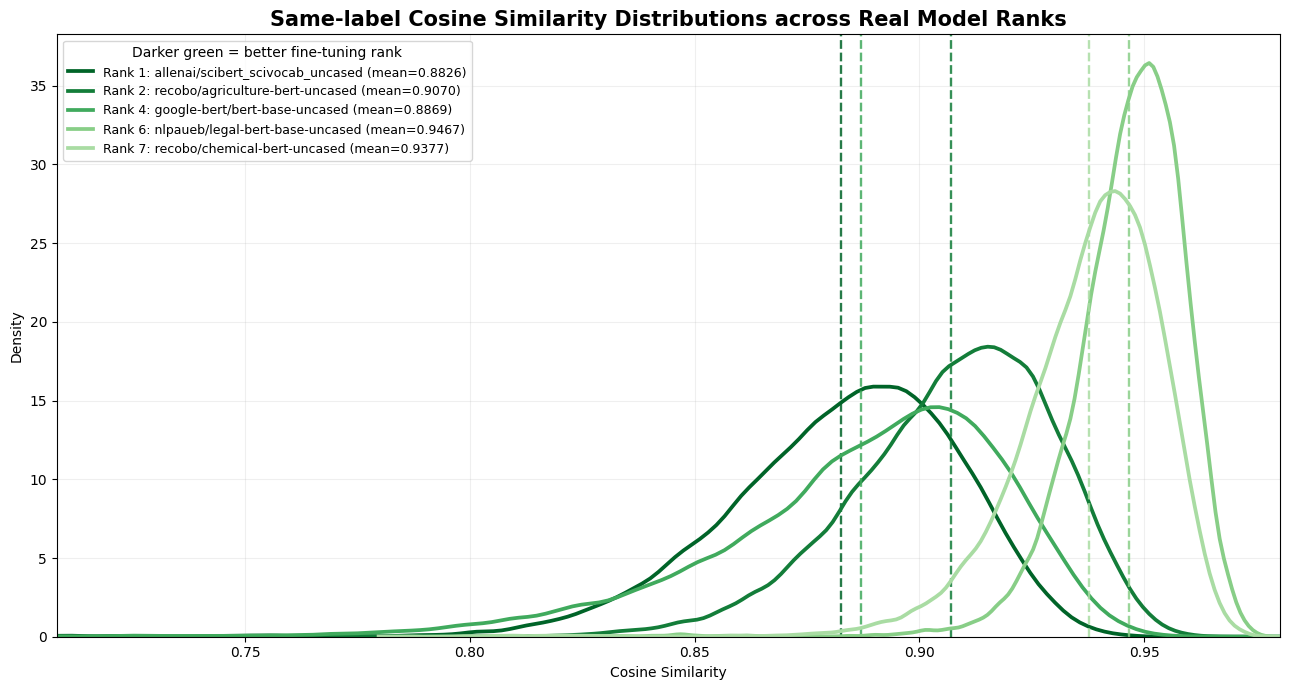

In [66]:
plt.figure(
    figsize=(13, 7)
)

for model_name in selected_models:
    values = distribution_data[
        model_name
    ]

    real_rank = values[
        "real_rank"
    ]

    scores = values[
        "same_scores"
    ]

    mean_value = values[
        "same_mean"
    ]

    colour = rank_colours[
        real_rank
    ]

    model_label = (
        f"Rank {real_rank}: "
        f"{model_name} "
        f"(mean={mean_value:.4f})"
    )

    sns.kdeplot(
        scores,
        color=colour,
        linewidth=2.7,
        bw_adjust=0.8,
        clip=(-1, 1),
        cut=0,
        label=model_label,
    )

    # Mean position
    plt.axvline(
        mean_value,
        color=colour,
        linestyle="--",
        linewidth=1.7,
        alpha=0.85,
    )

plt.xlim(
    display_minimum,
    display_maximum,
)

plt.xlabel(
    "Cosine Similarity"
)

plt.ylabel(
    "Density"
)

plt.title(
    "Same-label Cosine Similarity "
    "Distributions across Real Model Ranks",
    fontsize=15,
    fontweight="bold",
)

plt.legend(
    fontsize=9,
    title=(
        "Darker green = better "
        "fine-tuning rank"
    ),
)

plt.grid(
    alpha=0.2
)

plt.tight_layout()

plt.savefig(
    "arxiv_same_label_rank_spanning.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

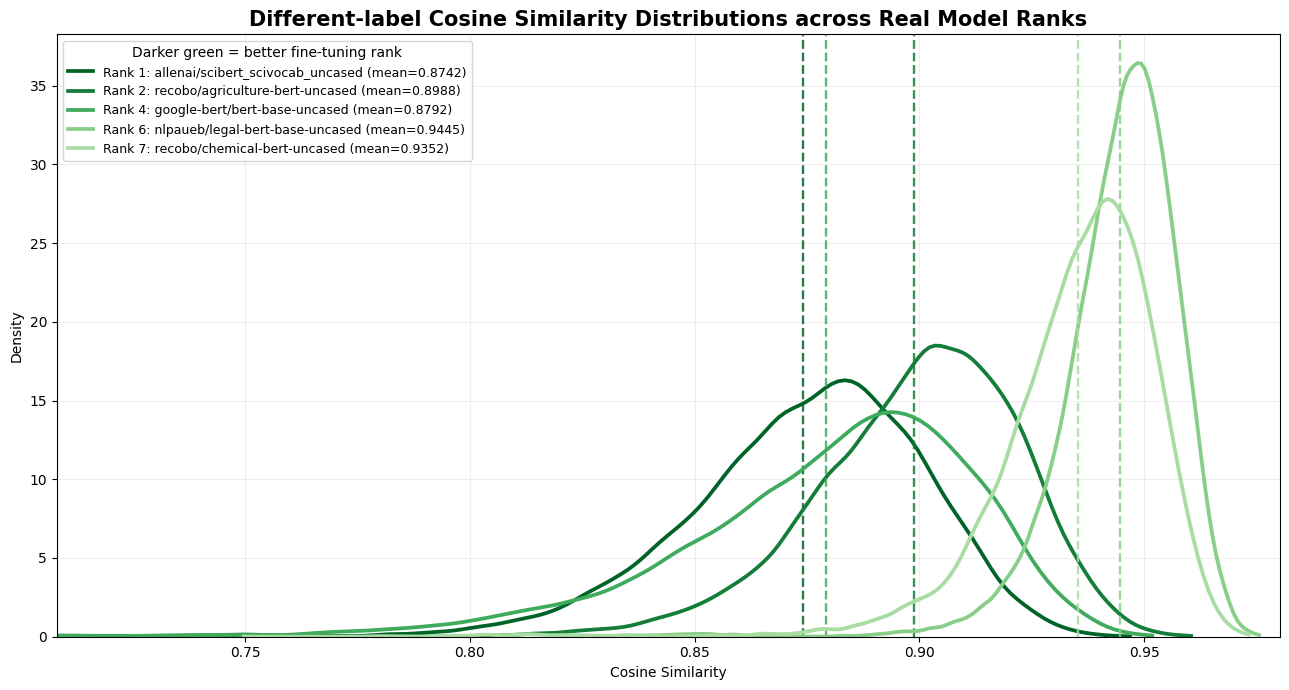

In [67]:
plt.figure(
    figsize=(13, 7)
)

for model_name in selected_models:
    values = distribution_data[
        model_name
    ]

    real_rank = values[
        "real_rank"
    ]

    scores = values[
        "diff_scores"
    ]

    mean_value = values[
        "diff_mean"
    ]

    colour = rank_colours[
        real_rank
    ]

    model_label = (
        f"Rank {real_rank}: "
        f"{model_name} "
        f"(mean={mean_value:.4f})"
    )

    sns.kdeplot(
        scores,
        color=colour,
        linewidth=2.7,
        bw_adjust=0.8,
        clip=(-1, 1),
        cut=0,
        label=model_label,
    )

    # Mean position
    plt.axvline(
        mean_value,
        color=colour,
        linestyle="--",
        linewidth=1.7,
        alpha=0.85,
    )

plt.xlim(
    display_minimum,
    display_maximum,
)

plt.xlabel(
    "Cosine Similarity"
)

plt.ylabel(
    "Density"
)

plt.title(
    "Different-label Cosine Similarity "
    "Distributions across Real Model Ranks",
    fontsize=15,
    fontweight="bold",
)

plt.legend(
    fontsize=9,
    title=(
        "Darker green = better "
        "fine-tuning rank"
    ),
)

plt.grid(
    alpha=0.2
)

plt.tight_layout()

plt.savefig(
    (
        "arxiv_different_label_"
        "rank_spanning.png"
    ),
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [68]:
def predict_model_ranking(metric_summary_df):
    # RankPredict 的列名，以及 grid search 得到的系数
    coefficients = {
        "same_mean_mean": -0.2,
        "diff_mean_mean": 0.2,
        "same_abs_eta_mean": -0.4,
        "diff_abs_eta_mean": 0.1,
        "chi2_distance_mean": -0.1,
    }

    result = metric_summary_df.copy()
    metrics = list(coefficients)

    # 在当前数据集的候选模型之间进行 Z-score 标准化
    values = result[metrics]
    std = values.std(ddof=0)

    scaled = (
        (values - values.mean())
        / std.mask(np.isclose(std, 0), 1.0)
    )

    # 线性组合：Score = Σ coefficient × standardized metric
    result["PredictionScore"] = (
        scaled.mul(pd.Series(coefficients))
        .sum(axis=1)
        .round(12)
    )

    result["PredictedRank"] = result["PredictionScore"].rank(
        ascending=False,
        method="average",
    )

    return result[
        ["model", "PredictionScore", "PredictedRank"]
    ].sort_values("PredictedRank")

In [69]:
predicted_ranking = predict_model_ranking(metric_summary_df)
display(predicted_ranking)

,model,PredictionScore,PredictedRank
1,ahmedrachid/FinancialBERT,0.402106,1.0
4,nlpaueb/legal-bert-base-uncased,0.374197,2.0
2,allenai/scibert_scivocab_uncased,0.248336,3.0
6,recobo/chemical-bert-uncased,0.028545,4.0
0,Lianglab/PharmBERT-uncased,-0.044286,5.0
5,recobo/agriculture-bert-uncased,-0.162095,6.0
3,google-bert/bert-base-uncased,-0.846803,7.0
